# 03 — CaSR rotated-pole grid vs. wind quiver

Drawing arrows with `quiver(angles="xy")` on the rlon/rlat axes of the maps (default mode) leads to difference in interpretation for the true orientation of the climatic averaged monthly mean wind vector direction. The long_name of the uas and vas fields state that they are eastward and northward winds. Computing wind direction from these fields truly gives a cardinal orientation but placed on the rotated pole grid, this leads to the wrong bearing. Each cell's value is rotated by an angle in order for the east and north winds not to follow the
grid axes but the parallels and meridians.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

CACHE_PATH = Path.home() / "data" / "ECCC" / "casr_v32_day_egsl_19900901-20200901.nc"
QUIVER_STRIDE, ARROW_FILL = 8, 0.8      # as in src/plotting.py at commit 04d6101

ds = xr.open_dataset(CACHE_PATH)
sftof, lat, lon = ds.sftof.load(), ds.lat.load(), ds.lon.load()

In [2]:
def quiver_unrotated(ax, u, v):
    """Equal-length arrows with (u, v) taken as steps along rlon/rlat: src/plotting.py quiver at commit 04d6101."""
    sub = xr.Dataset({"u": u, "v": v}).isel(rlat=slice(None, None, QUIVER_STRIDE), rlon=slice(None, None, QUIVER_STRIDE))
    norm = np.hypot(sub.u, sub.v)
    spacing = abs(float(sub.rlon[1] - sub.rlon[0]))
    ax.quiver(sub.rlon, sub.rlat, sub.u / norm, sub.v / norm, color="white", edgecolor="k", linewidth=0.4,
              angles="xy", scale_units="xy", scale=1 / (ARROW_FILL * spacing), pivot="middle")

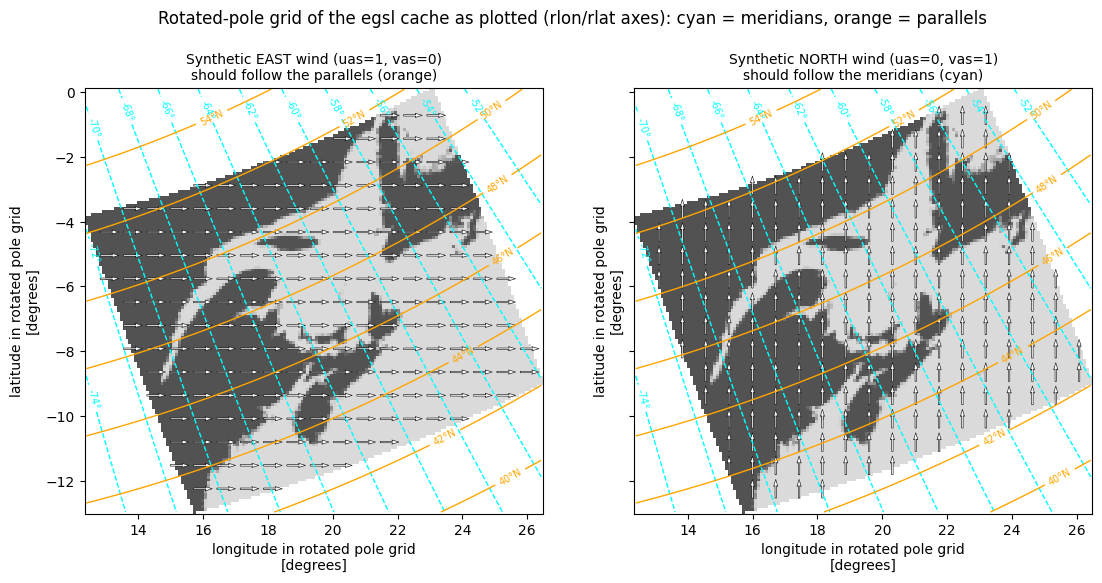

In [3]:
ones, zeros = xr.ones_like(sftof).where(sftof.notnull()), xr.zeros_like(sftof).where(sftof.notnull())
tests = {"Synthetic EAST wind (uas=1, vas=0)\nshould follow the parallels (orange)": (ones, zeros),
         "Synthetic NORTH wind (uas=0, vas=1)\nshould follow the meridians (cyan)": (zeros, ones)}
fig, axs = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, (title, (u, v)) in zip(axs, tests.items()):
    sftof.plot(ax=ax, cmap="Greys_r", vmin=-0.5, vmax=1.5, add_colorbar=False)    # land dark grey, sea light
    cl = ax.contour(lon.rlon, lon.rlat, lon, levels=np.arange(-74, -50, 2), colors="cyan", linewidths=1)
    ax.clabel(cl, fmt="%d°", fontsize=7)
    cp = ax.contour(lat.rlon, lat.rlat, lat, levels=np.arange(40, 56, 2), colors="orange", linewidths=1)
    ax.clabel(cp, fmt="%d°N", fontsize=7)
    quiver_unrotated(ax, u, v)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
fig.suptitle("Rotated-pole grid of the egsl cache as plotted (rlon/rlat axes): cyan = meridians, orange = parallels");